# Timeseries — Klasifikasi Deret Waktu
**Kapan dipakai:** tiap baris = satu deret pendek (sinyal gerakan, detak jantung, sensor) dan
diminta menebak kelasnya. Kolom `t0`, `t1`, ... = nilai di tiap waktu.

**Langkah:** plot rata-rata deret per kelas → split dari data latih → model → evaluasi →
latih ulang di semua data latih → submission.

**Data demo:** GunPoint (`label`, 150 titik per deret). Dataset lain: ItalyPower =
`italy_power_train.csv` / `italy_power_test.csv` dengan `SERIES_LENGTH = 24`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier
from sktime.classification.interval_based import TimeSeriesForestClassifier
from sktime.classification.kernel_based import RocketClassifier

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/timeseries/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/gunpoint_train.csv"
TEST_CSV = f"{DATA_FOLDER}/gunpoint_test.csv"

LABEL_COL = "label"
SERIES_LENGTH = 150       # titik per deret: GunPoint 150, ItalyPower 24
FEATURE_COLS = []
for i in range(SERIES_LENGTH):
    FEATURE_COLS.append(f"t{i}")
SEED = 42

## Baca data dan EDA

(50, 151) (150, 151)
missing latih: 0 | uji: 0
label
2    26
1    24
Name: count, dtype: int64


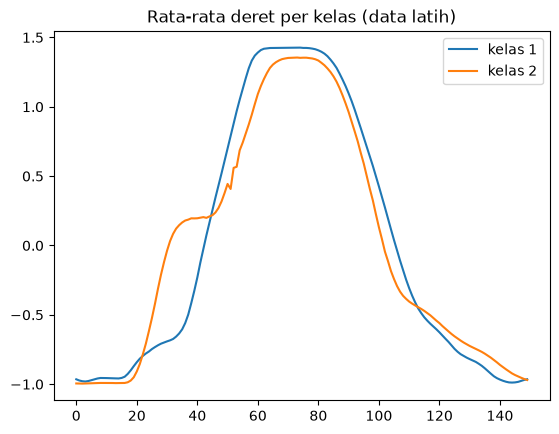

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
train_missing = train.isna().sum()
test_missing = test.isna().sum()
print("missing latih:", train_missing.sum(), "| uji:", test_missing.sum())
print(train[LABEL_COL].value_counts())

for label, group in train.groupby(LABEL_COL):
    plt.plot(group[FEATURE_COLS].mean().to_numpy(), label=f"kelas {label}")
plt.title("Rata-rata deret per kelas (data latih)")
plt.legend()
plt.show()

## Split
Tiap baris = satu deret yang berdiri sendiri (tidak ada urutan waktu antar baris), jadi boleh
diacak. Data latih GunPoint hanya 50 baris, skor validasi masih naik-turun.

In [4]:
X = train[FEATURE_COLS].to_numpy()
y = train[LABEL_COL].to_numpy()
X_test = test[FEATURE_COLS].to_numpy()
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, stratify=y,
                                                  random_state=SEED)
print("latih:", X_train.shape, "| validasi:", X_val.shape)

latih: (35, 150) | validasi: (15, 150)


## Alternatif: model berbasis fitur (tsfresh)
Tiap deret diringkas jadi ratusan fitur (rata-rata, puncak, autokorelasi, entropi, FFT, ...),
lalu model tabular biasa. Hapus `#` di sel ini, X_train/X_val/X_test diganti matriks fitur.

In [5]:
# from tsfresh import extract_features
# from tsfresh.feature_extraction import EfficientFCParameters
# from tsfresh.utilities.dataframe_functions import impute
#
#
# def tsfresh_features(matrix):
#     # matriks (deret x waktu) → tabel panjang: series_id, time, value → fitur per deret
#     long = pd.DataFrame(matrix)
#     long["series_id"] = range(len(long))
#     long = long.melt(id_vars="series_id", var_name="time", value_name="value")
#     features = extract_features(long, column_id="series_id", column_sort="time",
#                                 default_fc_parameters=EfficientFCParameters(),
#                                 n_jobs=0, disable_progressbar=True)
#     return impute(features)
#
#
# X_train = tsfresh_features(X_train)
# X_val = tsfresh_features(X_val)[X_train.columns]
# X_test = tsfresh_features(X_test)[X_train.columns]
# print("jumlah fitur:", X_train.shape[1])

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris RandomForest.
KNN-DTW = tetangga terdekat dengan jarak yang boleh bergeser di sumbu waktu.
Rocket (MiniRocket) = ribuan filter konvolusi acak + model linear.

In [6]:
model = RandomForestClassifier(n_estimators=500, random_state=SEED)
# model = KNeighborsClassifier(n_neighbors=1)
# model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
# model = KNeighborsTimeSeriesClassifier(n_neighbors=1, distance="dtw")
# model = RocketClassifier(rocket_transform="minirocket", random_state=SEED)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED)
# model = TimeSeriesForestClassifier(n_estimators=200, random_state=SEED)
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = LGBMClassifier(n_estimators=300, verbose=-1, random_state=SEED)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## Evaluasi (data validasi)

akurasi: 1.0
F1 macro: 1.0
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         7
           2       1.00      1.00      1.00         8

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



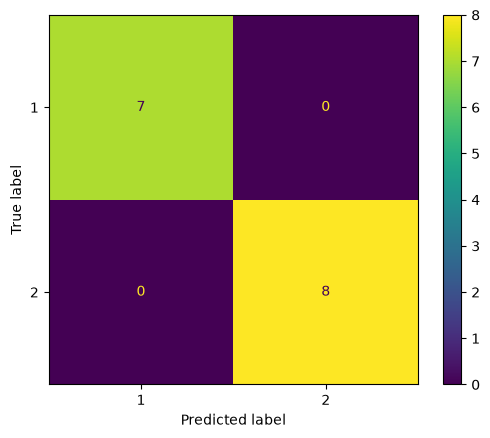

In [7]:
val_predictions = model.predict(X_val)
print("akurasi:", round(accuracy_score(y_val, val_predictions), 4))
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions)
plt.show()

## Latih ulang di semua data latih + submission
File test tidak punya kolom id, jadi `id` = nomor baris test.

In [8]:
final_model = clone(model)
final_model.fit(X, y)
predictions = final_model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = range(len(test))
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,0,1
1,1,2
2,2,2
3,3,1
4,4,1


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
File test demo masih memuat kolom `label`.

In [9]:
print("akurasi test:", round(accuracy_score(test[LABEL_COL], predictions), 4))
print("F1 macro test:", round(f1_score(test[LABEL_COL], predictions, average="macro"), 4))

akurasi test: 0.9333
F1 macro test: 0.9331
